# Worked solutions — Visualize data and explain the result

**Stage:** Applied Python · **Suggested time:** 45–90 minutes (capstone: several sessions)

**Prerequisites:** Concepts from notebooks 00–20. No variables or files from other notebooks are required.

## What you will learn

- Choose a chart for a question
- Label axes and units
- Create and inspect a multi-panel figure


This notebook contains complete worked answers. Try the corresponding learning notebook first. These are possible solutions, not the only correct approaches. Run from the top so all examples and answer checks execute.


## 1. Compare categories

Use a bar chart to compare categories. Name the measure and its units. A zero baseline makes bar lengths interpretable. The object-oriented matplotlib API keeps each axis explicit.


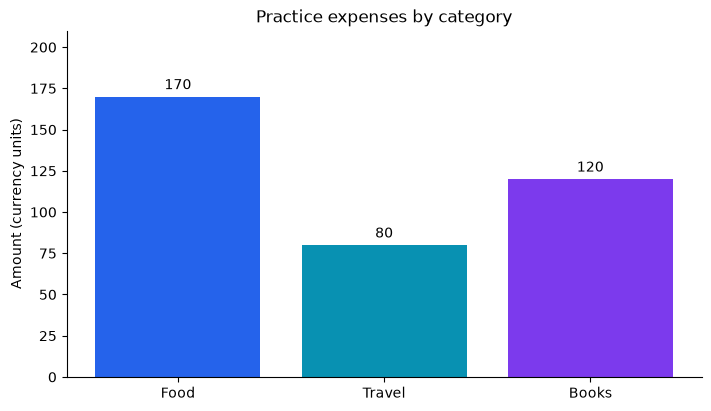

In [1]:
import matplotlib.pyplot as plt
categories = ["Food", "Travel", "Books"]
amounts = [170, 80, 120]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(categories, amounts, color=["#2563eb", "#0891b2", "#7c3aed"])
ax.bar_label(bars, padding=3)
ax.set(title="Practice expenses by category", ylabel="Amount (currency units)")
ax.set_ylim(0, 210)
ax.spines[["top", "right"]].set_visible(False)
plt.show()


**Try a change:** Change one value. Update the y limit if necessary so labels stay inside the figure.


## 2. Change over time and distributions

A line chart shows ordered change; a histogram shows a distribution. These answer different questions. Histogram bins affect the appearance, and a small dataset does not justify strong general conclusions.


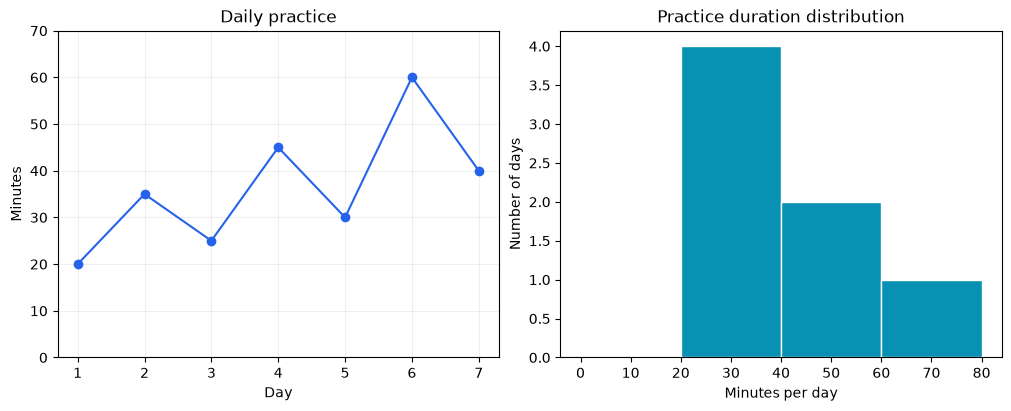

In [2]:
days = [1, 2, 3, 4, 5, 6, 7]
minutes = [20, 35, 25, 45, 30, 60, 40]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(days, minutes, marker="o", color="#2563eb")
axes[0].set(title="Daily practice", xlabel="Day", ylabel="Minutes", ylim=(0, 70))
axes[0].grid(alpha=0.2)
axes[1].hist(minutes, bins=[0, 20, 40, 60, 80], edgecolor="white", color="#0891b2")
axes[1].set(title="Practice duration distribution", xlabel="Minutes per day", ylabel="Number of days")
plt.show()


**Try a change:** Compare different bin widths. Write one claim supported by the line chart.


## 3. Export a figure

Save the figure object before closing it. Here a temporary PNG verifies the export without leaving generated files around. For your own report, choose a path under a practice_output folder and inspect the saved image.


PNG export created: True


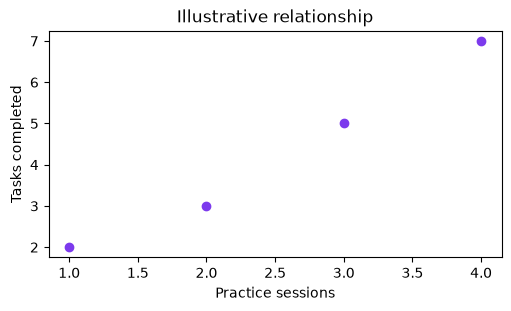

In [3]:
from pathlib import Path
from tempfile import TemporaryDirectory
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.scatter([1, 2, 3, 4], [2, 3, 5, 7], color="#7c3aed")
ax.set(title="Illustrative relationship", xlabel="Practice sessions", ylabel="Tasks completed")
with TemporaryDirectory() as folder:
    image_path = Path(folder) / "practice.png"
    fig.savefig(image_path, dpi=150)
    print("PNG export created:", image_path.stat().st_size > 0)
plt.show()
plt.close(fig)


**Try a change:** Explain why this invented scatter plot cannot establish that practice caused the outcome.


## Practice: solve before looking at the answers

Replace the starter code with your implementation. Run it, then change that exercise's `exercise_N_ready` flag to `True` and run its check cell. A failed assertion is feedback: compare the expected value with your result. Add at least one test of your own.


### Exercise 1: Cumulative values

Implement cumulative(values) returning running totals for a line chart.

<details>
<summary>Show a hint</summary>

Accumulate and append at each step.

</details>


In [4]:
def cumulative(values):
    result = []
    total = 0
    for value in values:
        total += value
        result.append(total)
    return result


In [5]:
exercise_1_ready = True  # Set True when your implementation is ready.
if exercise_1_ready:
    assert cumulative([2, 3, 5]) == [2, 5, 10]
    assert cumulative([]) == []
    print("Exercise 1: supplied checks passed. Add your own edge cases!")
else:
    print("Exercise 1: not checked yet. Complete the code, then set exercise_1_ready = True.")


Exercise 1: supplied checks passed. Add your own edge cases!


### Exercise 2: A labeled chart function

Implement make_bar_chart(labels, values) returning (fig, ax), with a bar for each value, title 'Expense comparison', and y-label 'Amount'. Do not call show() inside the function.

<details>
<summary>Show a hint</summary>

Use plt.subplots(), ax.bar(), and ax.set().

</details>


In [6]:
def make_bar_chart(labels, values):
    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    ax.bar(labels, values)
    ax.set(title="Expense comparison", ylabel="Amount")
    return fig, ax


In [7]:
exercise_2_ready = True  # Set True when your implementation is ready.
if exercise_2_ready:
    test_fig, test_ax = make_bar_chart(["A", "B"], [10, 20])
    assert test_ax.get_title() == "Expense comparison"
    assert test_ax.get_ylabel() == "Amount"
    assert [bar.get_height() for bar in test_ax.patches] == [10, 20]
    plt.close(test_fig)
    print("Exercise 2: supplied checks passed. Add your own edge cases!")
else:
    print("Exercise 2: not checked yet. Complete the code, then set exercise_2_ready = True.")


Exercise 2: supplied checks passed. Add your own edge cases!


## Build it yourself

Make a two-chart practice dashboard: daily minutes and cumulative minutes. Label units, use readable text, export a PNG, and write two observations plus one limitation. Inspect the image at its actual display size.

This open-ended extension has no single supplied solution. Record your design choices and test your result.


In [8]:
# Your mini-project workspace. Add more cells as needed.


## Common mistakes and limits

A beautiful chart can still mislead. Avoid distorted bar baselines, missing units, and claims stronger than the data. Close figures when generating many plots in a loop.


## Before you move on

- [ ] I can explain the examples without reading the code.
- [ ] I changed at least two inputs and predicted the results.
- [ ] I completed both exercises and enabled their checks.
- [ ] I added a boundary or failure case of my own.
- [ ] I attempted the mini-project and recorded one lesson learned.

**Reflection:** What surprised you? What would you try next? Edit this Markdown cell with your notes.


[Course guide](../README.md) · [Back to learning notebook](../notebooks/21_matplotlib_visualization.ipynb)
